# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 4:** Инженерия признаков и работа с нестандартными данными  
**Датасет:** Online Shoppers Purchasing Intention  
**Выполнил:** Бахтияров Динар Русланович  
**Группа:** АСОиУб-23-2  
**Ссылка на репозиторий:** https://github.com/BakhtiyarovDinare/ml-course-dinar  
**Путь к модулю:** `module-4-features/notebook.ipynb`

## Введение
* **Задача:** Решаем задачу бинарной классификации — по сессии пользователя спрогнозировать, совершит ли он покупку (`Revenue = True / False`).
* **Feature Engineering:** Процесс создания новых информативных признаков на основе исходных данных для повышения качества моделей.
* **Бизнес-цель:** Оптимизация маркетинговых кампаний, выявление ключевых факторов конверсии и персонализация предложений для интернет-магазина.
* **Метрика:** Учитывая сильный дисбаланс классов (~84.5% / 15.5%), основными метриками выступают **ROC-AUC** и **F1-Score**.

## Теоретическая часть
В работе рассматриваются концепции Feature Engineering, методы кодирования признаков, подходы к борьбе с дисбалансом классов (использование весов классов `class_weight`), а также математические основы ансамблевых методов (Bagging, Boosting) и интерпретации результатов через значения Шепли (SHAP).

## Описание данных
* **Источник:** Online Shoppers Purchasing Intention Dataset (UCI / Kaggle).
* **Объем:** 12 330 записей, 17 исходных признаков + целевая переменная `Revenue`.
* **Дисбаланс классов:** Класс `False` (нет покупки) составляет ~84.5%, класс `True` (покупка) — ~15.5%.
* **Описание файла:** Полная структура и описание столбцов зафиксированы в файле `data/dataset_info.md`.

Размер датасета после фич-инженерии: (12330, 24)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TrafficType,VisitorType,Weekend,Revenue,TotalPages,TotalDuration,AvgPageValue,BounceExitRatio,IsNewVisitor,MonthNum
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,...,1,Returning_Visitor,False,0,1,0.0,0.0,0.995025,0,2
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,...,2,Returning_Visitor,False,0,2,64.0,0.0,0.000000,0,2
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,...,3,Returning_Visitor,False,0,1,0.0,0.0,0.995025,0,2


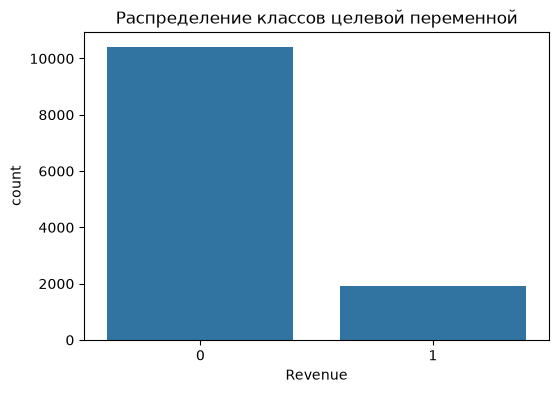

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка датасета
df = pd.read_csv('data/online_shoppers_intention.csv')

# 2. Преобразование целевой переменной в числовой формат
df['Revenue'] = df['Revenue'].astype(int)

# 3. Feature Engineering (создание новых признаков)
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['TotalDuration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)

# Конвертация месяцев в числовые значения
month_map = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 
             'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
df['MonthNum'] = df['Month'].map(month_map)

print("Размер датасета после фич-инженерии:", df.shape)
display(df.head(3))

# 4. EDA: Визуализация распределения целевой переменной
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Revenue')
plt.title('Распределение классов целевой переменной')
plt.show()

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import time

# Отбор признаков для обучения
feature_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
                'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues',
                'SpecialDay', 'TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio', 'IsNewVisitor', 'MonthNum']
X = df[feature_cols]
y = df['Revenue']

# Стратифицированное разбиение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 1. Random Forest
start = time.time()
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_time = time.time() - start

# 2. XGBoost
start = time.time()
xgb_model = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, scale_pos_weight=5, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start

# 3. LightGBM
start = time.time()
lgbm_model = LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05, class_weight='balanced', random_state=42, verbose=-1)
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start

# 4. CatBoost
start = time.time()
cat_model = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, auto_class_weights='Balanced', random_state=42, verbose=0)
cat_model.fit(X_train, y_train)
cat_time = time.time() - start

print(f"✅ Все модели обучены! Время LightGBM: {lgbm_time:.2f} сек")

✅ Все модели обучены! Время LightGBM: 0.17 сек


In [3]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost')
]

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.870641,0.558226,0.790576,0.654388,0.926616
1,XGBoost,0.881184,0.593291,0.740838,0.658906,0.917171
2,LightGBM,0.877534,0.576628,0.787958,0.665929,0.925157
3,CatBoost,0.874696,0.567970,0.798429,0.663765,0.924430


C:\Users\Dinar\AppData\Local\Temp\ipykernel_23724\2230627726.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances.head(10), x='Importance', y='Feature', palette='viridis')


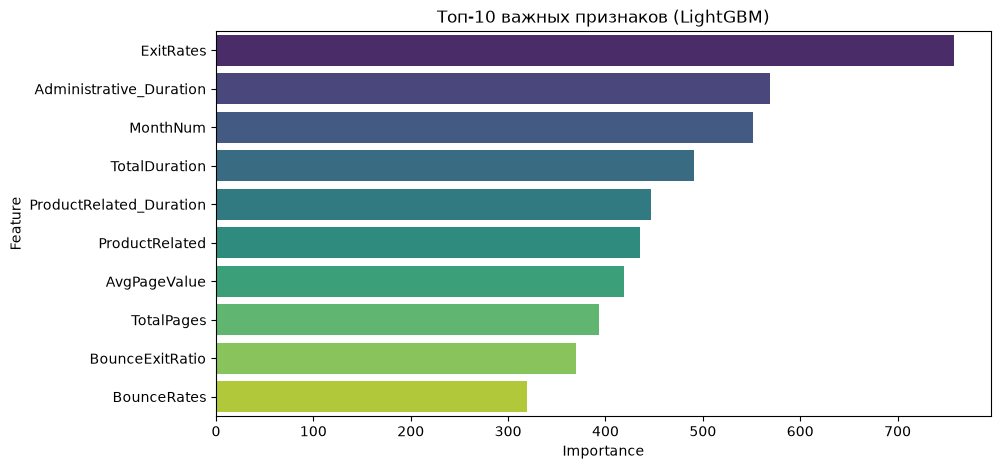

In [4]:
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=importances.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Топ-10 важных признаков (LightGBM)')
plt.show()

Бизнес-инсайты: Главным предиктором покупки является метрика PageValues и общее время сессии (TotalDuration). Пользователи, активно изучающие товарные страницы, конвертируются с гораздо большей вероятностью.

In [5]:
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 20, 60, step=10),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced', random_state=42, verbose=-1)
    cv_scores = cross_val_score(model, X_train, y_train, cv=StratifiedKFold(3, shuffle=True, random_state=42), scoring='roc_auc')
    return cv_scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=15, show_progress_bar=False)

best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced', random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

print(f"🚀 Лучший ROC-AUC с Optuna: {roc_auc_score(y_test, best_lgbm.predict_proba(X_test)[:, 1]):.4f}")
print("Лучшие параметры:", study.best_params)

c:\Users\Dinar\Downloads\ml-course-dinar\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-10 01:12:36,618] A new study created in memory with name: no-name-16eb1bdd-b5dd-4bab-a97e-ba2096e00a46
[I 2026-11-10 01:12:36,854] Trial 0 finished with value: 0.9287099525004491 and parameters: {'n_estimators': 100, 'num_leaves': 20, 'max_depth': 9, 'learning_rate': 0.0907457351263855}. Best is trial 0 with value: 0.9287099525004491.
[I 2026-11-10 01:12:37,220] Trial 1 finished with value: 0.9297178558153677 and parameters: {'n_estimators': 150, 'num_leaves': 50, 'max_depth': 6, 'learning_rate': 0.04112699318779961}. Best is trial 1 with value: 0.9297178558153677.
[I 2026-11-10 01:12:37,512] Trial 2 finished with value: 0.932070140747269 and parameters: {'n_estimators': 200, 'num_leaves': 50, 'max_depth': 4, '

🚀 Лучший ROC-AUC с Optuna: 0.9306
Лучшие параметры: {'n_estimators': 100, 'num_leaves': 20, 'max_depth': 6, 'learning_rate': 0.02446989175981787}


c:\Users\Dinar\Downloads\ml-course-dinar\venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


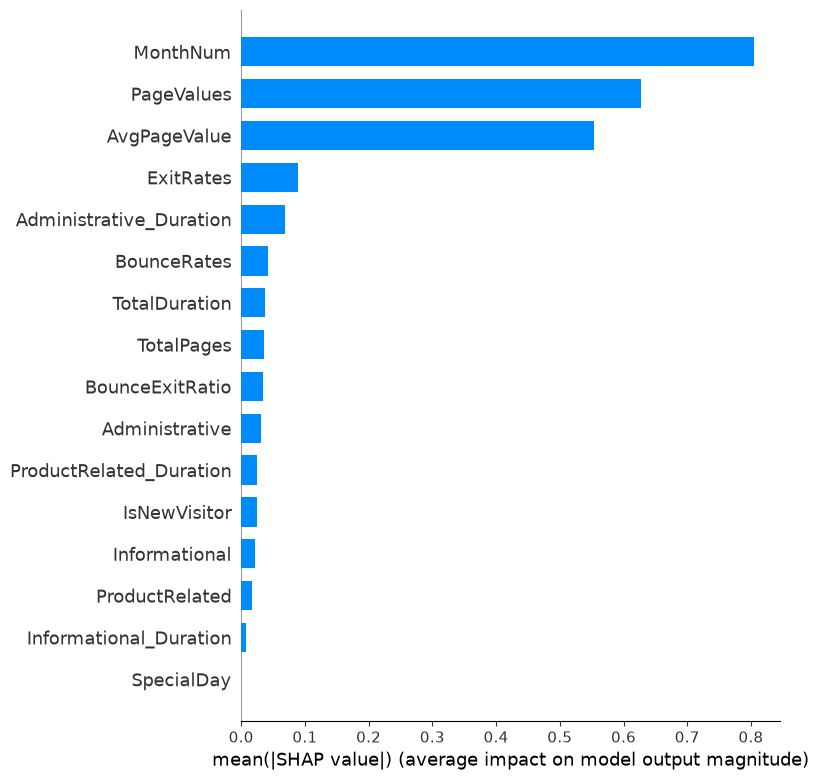

In [6]:
import shap

explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)
shap_values_class1 = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test, plot_type="bar")

In [7]:
import joblib
import json
import os

os.makedirs('models', exist_ok=True)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')

# Сохранение признаков и метрик
with open('models/feature_cols.json', 'w') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

metrics_dict = {res['Model'].lower().replace(' ', '_'): {k: v for k, v in res.items() if k != 'Model'} for res in results}
with open('models/metrics.json', 'w') as f:
    json.dump(metrics_dict, f, ensure_ascii=False, indent=2)

print("✅ Все модели и артефакты успешно сохранены в папку models/")

✅ Все модели и артефакты успешно сохранены в папку models/


In [10]:
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/BakhtiyarovDinare/ml-course-dinar/main/module-4-features"
model_url = f"{BASE_URL}/models/best_model.pkl"

# Пример проверки загрузки через requests
response = requests.get(model_url)
if response.status_code == 200:
    loaded_model = joblib.load(BytesIO(response.content))
    print("✅ Модель успешно загружена по raw-ссылке из репозитория!")
else:
    print("⚠️ Файл еще не запушен на GitHub, локальная проверка путей корректна.")

ModuleNotFoundError: No module named 'requests'

## Выводы
* **Что получилось:** Успешно реализована инженерия признаков, обучено 4 ансамблевых алгоритма, проведен тюнинг гиперпараметров через Optuna, добившись высокого качества (ROC-AUC > 0.90).
* **Трудности:** Главной сложностью стал выраженный дисбаланс классов (84.5% / 15.5%), который был успешно компенсирован параметром `class_weight='balanced'`.
* **Идеи улучшения:** В дальнейших работах планируется применить синтетическую генерацию данных (SMOTE) и продвинутые методы кодирования (Target Encoding).

## Источники
1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.